# Verificacion Estacionariedad Spread

Este script está diseñado específicamente como una herramienta de diagnóstico rápida y ligera. No ejecuta un backtest completo, sino que se centra exclusivamente en validar la premisa fundamental del StatArb: la estacionariedad del spread, ahorrándote tiempo antes de comprometer capital.

## Celda 1: Importaciones y Configuración del Entorno

In [1]:
# Celda 1: Importaciones y Configuración del Entorno
# ==============================================================================
# SCRIPT DE DIAGNÓSTICO: Verificación de Estacionariedad del Spread (StatArb)
# ==============================================================================
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilo de gráficos
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 10)

print("✅ Entorno cargado correctamente. Listo para escanear pares ETF-Cesta.")

✅ Entorno cargado correctamente. Listo para escanear pares ETF-Cesta.


## Celda 2: Parámetros de la Prueba 

(Modificar aquí para nuevos pares)

In [2]:
# ==============================================================================
# PARÁMETROS DE LA PRUEBA
# ==============================================================================

# 1. Definición del Universo
ETF_TICKER = 'XLF'  # Ejemplo: Financial Select Sector SPDR Fund
CESTA_TICKERS = ['JPM', 'BAC', 'WFC', 'GS', 'MS', 'C', 'BLK', 'SCHW', 'AXP', 'PNC']

# 2. Período de análisis (Recomendado: al menos 3-5 años para detectar rupturas)
FECHA_INICIO = '2014-01-01'
FECHA_FIN = '2024-01-01' # Dejar en None para usar la fecha de hoy

# 3. Parámetros estadísticos
VENTANA_ZSCORE = 60       # Ventana móvil para calcular la media y desviación del spread
P_VALOR_MAXIMO = 0.10     # Umbral de significancia para el test ADF (10%)

print(f"🎯 Escaneando par: {ETF_TICKER} vs. Cesta de {len(CESTA_TICKERS)} activos")
print(f"📅 Período: {FECHA_INICIO} a {FECHA_FIN or 'Hoy'}")

🎯 Escaneando par: XLF vs. Cesta de 10 activos
📅 Período: 2014-01-01 a 2024-01-01


## Celda 3: Descarga y Limpieza de Datos

In [3]:
# ==============================================================================
# DESCARGA Y PREPROCESAMIENTO DE DATOS
# ==============================================================================
print("\n📥 Descargando datos de Yahoo Finance...")

# Descargar ETF
df_etf = yf.download(ETF_TICKER, start=FECHA_INICIO, end=FECHA_FIN, progress=False)['Close']
df_etf = pd.DataFrame(df_etf) # Asegurar que sea DataFrame
df_etf.columns = [ETF_TICKER]

# Descargar Cesta
df_cesta = yf.download(CESTA_TICKERS, start=FECHA_INICIO, end=FECHA_FIN, progress=False)['Close']

# Unir y limpiar
df = pd.concat([df_etf, df_cesta], axis=1).dropna()

if len(df) < 252:
    raise ValueError(f"❌ Datos insuficientes ({len(df)} días). Amplía el período de fechas.")

print(f"✅ Datos descargados y limpios: {len(df)} días hábiles.")


📥 Descargando datos de Yahoo Finance...
✅ Datos descargados y limpios: 2516 días hábiles.


## Celda 4: Cálculo del NAV Sintético y Spread Logarítmico

In [4]:
# ==============================================================================
# CÁLCULO DEL SPREAD LOGARÍTMICO
# ==============================================================================
print("\n📐 Calculando NAV sintético y Spread logarítmico...")

# 1. Normalizar precios a base 1.0 (Día 1 = 1.0)
df_norm = df / df.iloc[0]

# 2. Calcular NAV de la cesta (Pesos igualitarios para este diagnóstico rápido)
# Nota: En producción, aquí se aplicarían los pesos reales de capitalización del ETF.
cesta_cols = [col for col in df_norm.columns if col != ETF_TICKER]
df_norm['NAV_Sintetico'] = df_norm[cesta_cols].mean(axis=1)

# 3. Calcular Spread Logarítmico (evitando log(0))
spread = np.log(df_norm[ETF_TICKER].clip(lower=1e-10)) - np.log(df_norm['NAV_Sintetico'].clip(lower=1e-10))

print(f"✅ Spread calculado. Media: {spread.mean():.4f}, Desv. Estándar: {spread.std():.4f}")


📐 Calculando NAV sintético y Spread logarítmico...
✅ Spread calculado. Media: 0.0026, Desv. Estándar: 0.0457


## Celda 5: Test de Dickey-Fuller Aumentado (ADF)

In [5]:
# ==============================================================================
# TEST DE ESTACIONARIEDAD (ADF)
# ==============================================================================
print("\n🔬 Ejecutando Test de Dickey-Fuller Aumentado (ADF)...")

resultado_adf = adfuller(spread.dropna(), autolag='AIC')

nombres_salida = ['Estadístico ADF', 'p-valor', 'Nº de lags usados', 'Nº de observaciones']
resultados = pd.Series(resultado_adf[0:4], index=nombres_salida)

for key, value in resultado_adf[4].items():
    resultados[f'Valor crítico ({key})'] = value

print("\n📊 RESULTADOS DEL TEST ADF:")
print(f"   • Estadístico:  {resultados['Estadístico ADF']:.4f}")
print(f"   • p-valor:      {resultados['p-valor']:.4f}")
print(f"   • Observaciones:{int(resultados['Nº de observaciones'])}")

es_estacionario = resultados['p-valor'] < P_VALOR_MAXIMO

print("\n" + "="*70)
if es_estacionario:
    print("✅ CONCLUSIÓN: El spread ES estacionario.")
    print("   El par es un candidato VIABLE para Statistical Arbitrage.")
else:
    print("❌ CONCLUSIÓN: El spread NO es estacionario.")
    print("   ⚠️ ADVERTENCIA: Las desviaciones pueden ser permanentes (ruptura estructural).")
    print("   No se recomienda operar este par con pesos igualitarios en este período.")
print("="*70)


🔬 Ejecutando Test de Dickey-Fuller Aumentado (ADF)...

📊 RESULTADOS DEL TEST ADF:
   • Estadístico:  -2.2228
   • p-valor:      0.1981
   • Observaciones:2514

❌ CONCLUSIÓN: El spread NO es estacionario.
   ⚠️ ADVERTENCIA: Las desviaciones pueden ser permanentes (ruptura estructural).
   No se recomienda operar este par con pesos igualitarios en este período.


## Celda 6: Cálculo del Z-Score Rolling

In [6]:
# ==============================================================================
# CÁLCULO DEL Z-SCORE ROLLING
# ==============================================================================
# El Z-score nos dice cuántas desviaciones estándar está el spread actual de su media reciente.

spread_mean = spread.rolling(window=VENTANA_ZSCORE).mean()
spread_std = spread.rolling(window=VENTANA_ZSCORE).std()

z_score = (spread - spread_mean) / spread_std

print(f"✅ Z-score rolling calculado con ventana de {VENTANA_ZSCORE} días.")

✅ Z-score rolling calculado con ventana de 60 días.


## Celda 7: Visualización Gráfica del Diagnóstico

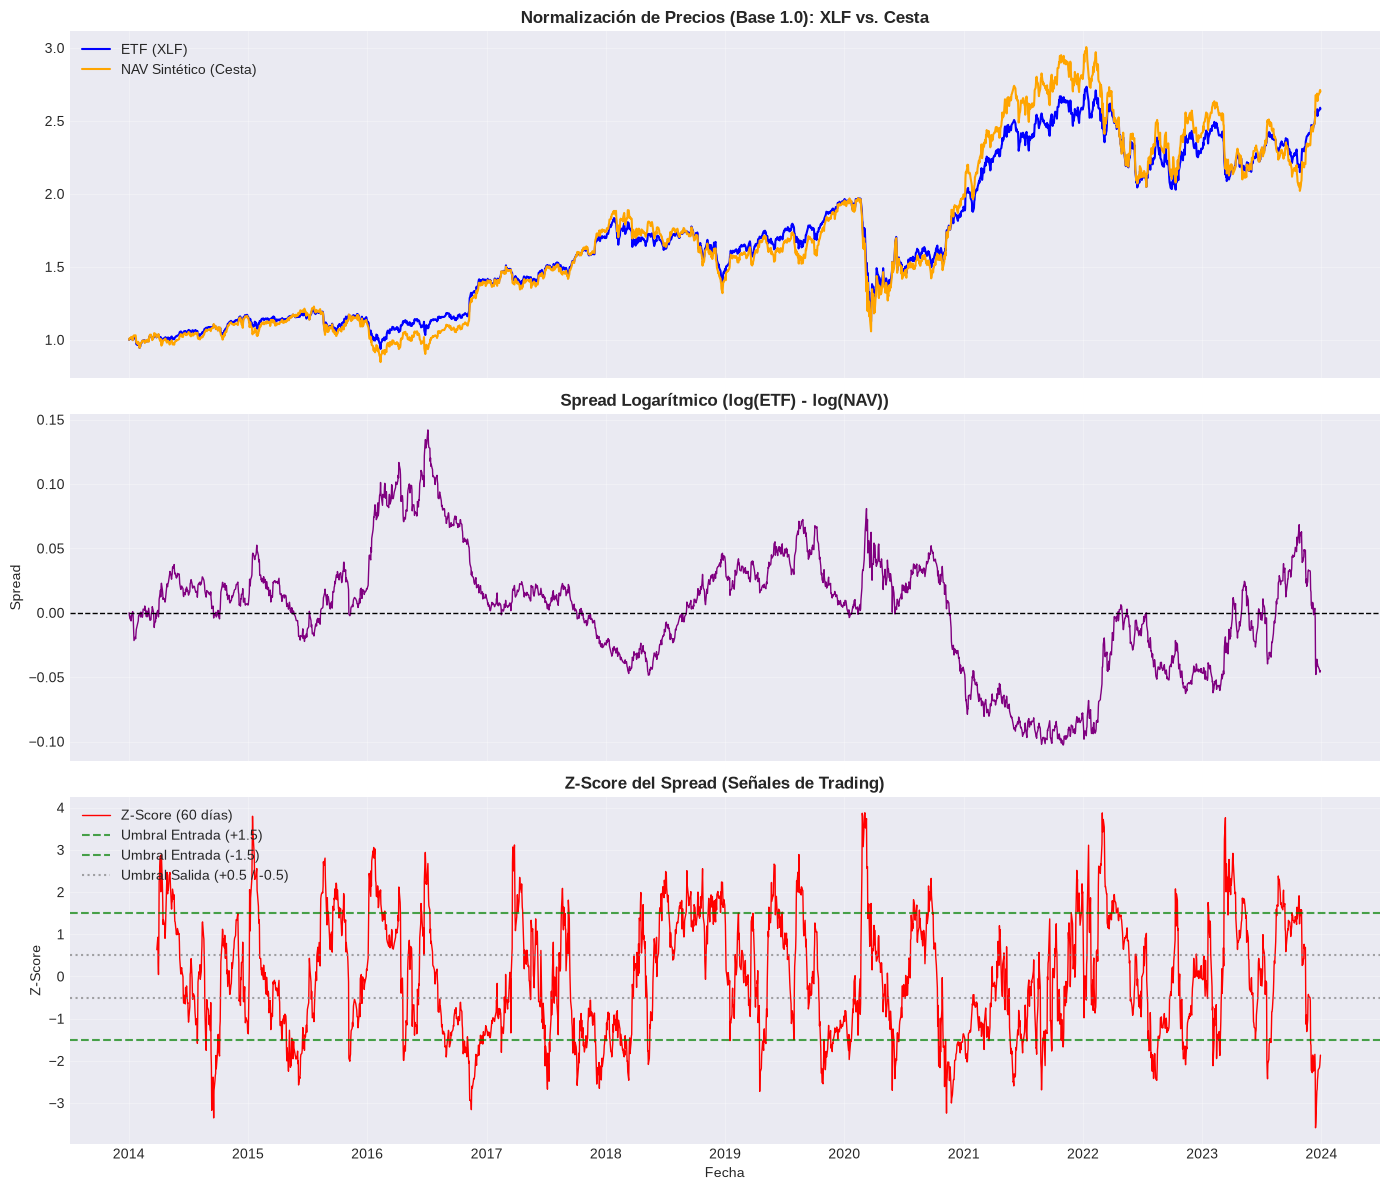

In [7]:
# ==============================================================================
# VISUALIZACIÓN DE RESULTADOS
# ==============================================================================
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Gráfico 1: Precios Normalizados
axes[0].plot(df_norm.index, df_norm[ETF_TICKER], label=f'ETF ({ETF_TICKER})', color='blue', lw=1.5)
axes[0].plot(df_norm.index, df_norm['NAV_Sintetico'], label='NAV Sintético (Cesta)', color='orange', lw=1.5)
axes[0].set_title(f'Normalización de Precios (Base 1.0): {ETF_TICKER} vs. Cesta', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Spread Logarítmico
axes[1].plot(spread.index, spread, label='Spread Logarítmico', color='purple', lw=1)
axes[1].axhline(0, color='black', linestyle='--', lw=1)
axes[1].set_title('Spread Logarítmico (log(ETF) - log(NAV))', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Spread')
axes[1].grid(True, alpha=0.3)

# Gráfico 3: Z-Score Rolling con Umbrales
axes[2].plot(z_score.index, z_score, label=f'Z-Score ({VENTANA_ZSCORE} días)', color='red', lw=1)
axes[2].axhline(1.5, color='green', linestyle='--', label='Umbral Entrada (+1.5)', alpha=0.7)
axes[2].axhline(-1.5, color='green', linestyle='--', label='Umbral Entrada (-1.5)', alpha=0.7)
axes[2].axhline(0.5, color='gray', linestyle=':', label='Umbral Salida (+0.5 / -0.5)', alpha=0.7)
axes[2].axhline(-0.5, color='gray', linestyle=':', alpha=0.7)
axes[2].set_title('Z-Score del Spread (Señales de Trading)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Z-Score')
axes[2].set_xlabel('Fecha')
axes[2].legend(loc='upper left')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Celda 8: Resumen Ejecutivo y Próximos Pasos

In [8]:
# ==============================================================================
# RESUMEN EJECUTIVO
# ==============================================================================
print("\n" + "="*70)
print("📝 RESUMEN EJECUTIVO DEL DIAGNÓSTICO")
print("="*70)

if es_estacionario:
    print("1. ✅ VALIDACIÓN ESTADÍSTICA: El p-valor es menor que 0.10.")
    print("   El spread muestra propiedades de reversión a la media.")
    print("2. 📊 OPORTUNIDAD: Observa el Gráfico 3. Si el Z-score toca frecuentemente ±1.5")
    print("   y regresa a 0, el par ofrece oportunidades de arbitraje.")
    print("3. ⚠️ SIGUIENTE PASO: Antes de operar, considera:")
    print("   - Ajustar los pesos de la cesta a la capitalización real del ETF.")
    print("   - Ejecutar un backtest completo con costes de transacción (Capítulo 6).")
else:
    print("1. ❌ VALIDACIÓN ESTADÍSTICA FALLIDA: El p-valor es mayor que 0.10.")
    print("   El spread tiene una raíz unitaria (tendencia o deriva).")
    print("2. 🚫 RIESGO: Apostar a la reversión a la media en este par es especulación,")
    print("   no arbitraje. El 'muelle' está roto o deformado permanentemente.")
    print("3. 💡 RECOMENDACIÓN: Descarta este par o prueba:")
    print("   - Un período de tiempo más corto (ej. últimos 2 años).")
    print("   - Otro ETF del mismo sector o un sector diferente (ej. XLE, XLK).")
    print("   - Usar los pesos reales de capitalización del ETF en lugar de igualitarios.")

print("="*70)


📝 RESUMEN EJECUTIVO DEL DIAGNÓSTICO
1. ❌ VALIDACIÓN ESTADÍSTICA FALLIDA: El p-valor es mayor que 0.10.
   El spread tiene una raíz unitaria (tendencia o deriva).
2. 🚫 RIESGO: Apostar a la reversión a la media en este par es especulación,
   no arbitraje. El 'muelle' está roto o deformado permanentemente.
3. 💡 RECOMENDACIÓN: Descarta este par o prueba:
   - Un período de tiempo más corto (ej. últimos 2 años).
   - Otro ETF del mismo sector o un sector diferente (ej. XLE, XLK).
   - Usar los pesos reales de capitalización del ETF en lugar de igualitarios.


## Cómo usar este script:

    Crea un nuevo archivo en VS Code llamado 06_Cap6_verificacion_estacionariedad_spread.ipynb.
    Copia y pega el contenido de arriba. VS Code reconocerá automáticamente los separadores de celdas si usas la extensión de Jupyter, o puedes copiar celda por celda.
    Para probar un nuevo par, solo tienes que modificar la Celda 2 (ETF_TICKER y CESTA_TICKERS) y volver a ejecutar todo el notebook desde arriba.
    En menos de 10 segundos, obtendrás el veredicto estadístico (p-valor) y 3 gráficos clave que te dirán visualmente si el "muelle" del spread funciona o está roto.

Este script cierra perfectamente el ciclo pedagógico del Capítulo 6, proporcionando la herramienta práctica que se menciona en las conclusiones del .md.